In [11]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [12]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

Y = np.array([
    [0],
    [1],
    [1],
    [0]
])

print("Input Dataset:")
print(X)

print("Expected Output:")
print(Y)

Input Dataset:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]
Expected Output:
[[0]
 [1]
 [1]
 [0]]


In [13]:
input_neurons = 2
hidden_neurons = 4
output_neurons = 1

# Random weight initialization
W1 = np.random.randn(input_neurons, hidden_neurons)
b1 = np.random.randn(1, hidden_neurons)

W2 = np.random.randn(hidden_neurons, output_neurons)
b2 = np.random.randn(1, output_neurons)

learning_rate = 1.0
epochs = 20000

print("Weights Initialized Successfully!")

Weights Initialized Successfully!


In [14]:
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))


def sigmoid_derivative(x):
    return x * (1 - x)

In [15]:
def forward_propagation(X):

    # Hidden layer
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)

    # Output layer
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    return a1, a2

In [16]:
errors = []

for epoch in range(epochs):

    # Forward propagation
    a1, a2 = forward_propagation(X)

    # Calculate Mean Squared Error
    error = np.mean((Y - a2) ** 2)
    errors.append(error)

    # Backpropagation
    delta_output = (
        (a2 - Y) * sigmoid_derivative(a2)
    )

    dW2 = np.dot(a1.T, delta_output) / len(X)
    db2 = np.mean(delta_output, axis=0, keepdims=True)

    delta_hidden = (
        np.dot(delta_output, W2.T) *
        sigmoid_derivative(a1)
    )

    dW1 = np.dot(X.T, delta_hidden) / len(X)
    db1 = np.mean(delta_hidden, axis=0, keepdims=True)

    # Update weights and biases
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if epoch % 2000 == 0:
        print(f"Epoch {epoch}, Error: {error:.6f}")

print("\nTraining Completed!")

Epoch 0, Error: 0.472302
Epoch 2000, Error: 0.005150
Epoch 4000, Error: 0.001603
Epoch 6000, Error: 0.000911
Epoch 8000, Error: 0.000629
Epoch 10000, Error: 0.000477
Epoch 12000, Error: 0.000383
Epoch 14000, Error: 0.000319
Epoch 16000, Error: 0.000273
Epoch 18000, Error: 0.000238

Training Completed!


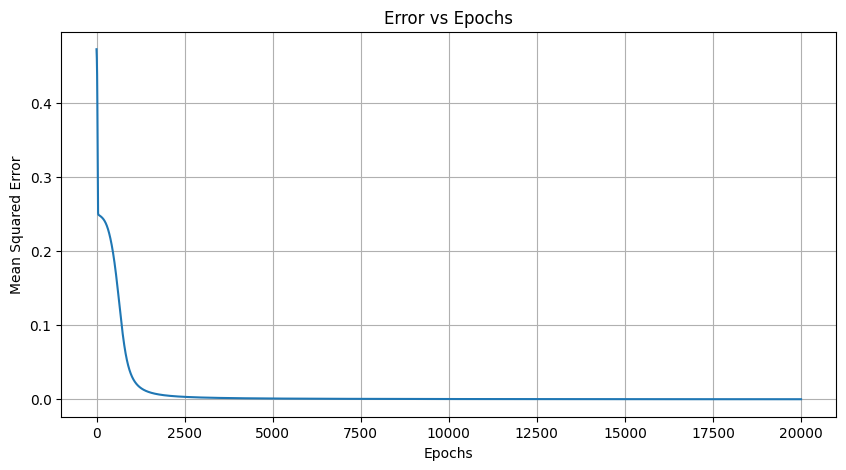

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(errors)

plt.title("Error vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.show()

In [18]:
_, predictions = forward_propagation(X)

print("XOR Predictions:\n")

for i in range(len(X)):

    predicted_value = predictions[i][0]

    output = 1 if predicted_value >= 0.5 else 0

    print(
        f"Input: {X[i]} | "
        f"Expected: {Y[i][0]} | "
        f"Predicted: {output} | "
        f"Probability: {predicted_value:.4f}"
    )

XOR Predictions:

Input: [0 0] | Expected: 0 | Predicted: 0 | Probability: 0.0122
Input: [0 1] | Expected: 1 | Predicted: 1 | Probability: 0.9851
Input: [1 0] | Expected: 1 | Predicted: 1 | Probability: 0.9858
Input: [1 1] | Expected: 0 | Predicted: 0 | Probability: 0.0165


In [19]:
test_data = np.array([
    [0.05, 0.05],
    [0.95, 0.05],
    [0.05, 0.95],
    [0.95, 0.95]
])

_, test_predictions = forward_propagation(test_data)

print("Testing on New Inputs:\n")

for i in range(len(test_data)):

    print(
        test_data[i],
        "->",
        round(test_predictions[i][0], 4)
    )

Testing on New Inputs:

[0.05 0.05] -> 0.0307
[0.95 0.05] -> 0.9858
[0.05 0.95] -> 0.9851
[0.95 0.95] -> 0.0267
